<a href="https://colab.research.google.com/github/Abdoulaye279/Financial-Engineering/blob/main/black-scholes-sp500/03_bootstrap_skew.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 - Pricing with the real S&P 500 returns

Reference that does not assume normality: 1-month paths built by drawing real daily returns at random (bootstrap), then the implied vol of each price.

In [1]:
# colab: get the repo first
try:
    import google.colab
    !git clone -q https://github.com/Abdoulaye279/Financial-Engineering
    %cd Financial-Engineering/black-scholes-sp500
except ImportError:
    pass

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from pricing import black_scholes, monte_carlo, binomial_crr, implied_vol
plt.style.use("quant.mplstyle")

df = pd.read_csv("data/sp500.csv")
df["Date"] = pd.to_datetime(df["Date"].str[:10])
prices = df.set_index("Date")["Close"].loc["2000":]
rets = np.log(prices).diff().dropna()

S0 = prices.iloc[-1]
sigma = rets.std() * np.sqrt(252)   # historical vol since 2000
r, T = 0.03, 21 / 252               # 3% rate, 1 month
print(len(rets), "days", rets.index[0].date(), "->", rets.index[-1].date(), "| S0", round(S0, 2), "| vol", round(sigma, 4))

6761 days 2000-01-04 -> 2026-11-19 | S0 7175.83 | vol 0.1924


In [3]:
rng = np.random.default_rng(0)
draws = rng.choice(rets.values - rets.mean(), size=(200_000, 21))
ST = S0 * np.exp(draws.sum(axis=1))
ST = ST * S0 * np.exp(r * T) / ST.mean()   # martingale correction, else not comparable with BS

strikes = [0.85, 0.88, 0.90, 0.93, 0.95, 0.97, 1.00, 1.03, 1.05, 1.08, 1.10]
ivs = []
for m in strikes:
    K = m * S0
    kind = "put" if m < 1 else "call"
    payoff = np.maximum(K - ST, 0) if kind == "put" else np.maximum(ST - K, 0)
    p_boot = np.exp(-r * T) * payoff.mean()
    p_bs = black_scholes(S0, K, T, r, sigma, kind)
    ivs.append(implied_vol(p_boot, S0, K, T, r, kind))
    print(f"K/S0={m}  {kind}  bootstrap={p_boot:.2f}  BS={p_bs:.2f}  ratio={p_boot/p_bs:.2f}  implied vol={ivs[-1]:.3f}")
# put at 85% of spot worth 3.7x the BS price: the fat left tail

K/S0=0.85  put  bootstrap=0.58  BS=0.16  ratio=3.74  implied vol=0.219
K/S0=0.88  put  bootstrap=2.27  BS=1.19  ratio=1.90  implied vol=0.210
K/S0=0.9  put  bootstrap=5.28  BS=3.74  ratio=1.41  implied vol=0.204
K/S0=0.93  put  bootstrap=17.11  BS=15.65  ratio=1.09  implied vol=0.197
K/S0=0.95  put  bootstrap=34.72  BS=34.31  ratio=1.01  implied vol=0.193
K/S0=0.97  put  bootstrap=65.47  BS=66.84  ratio=0.98  implied vol=0.190
K/S0=1.0  call  bootstrap=164.26  BS=167.92  ratio=0.98  implied vol=0.188
K/S0=1.03  call  bootstrap=78.05  BS=81.52  ratio=0.96  implied vol=0.188
K/S0=1.05  call  bootstrap=44.14  BS=46.21  ratio=0.96  implied vol=0.189
K/S0=1.08  call  bootstrap=17.23  BS=17.27  ratio=1.00  implied vol=0.192
K/S0=1.1  call  bootstrap=8.83  BS=8.19  ratio=1.08  implied vol=0.195


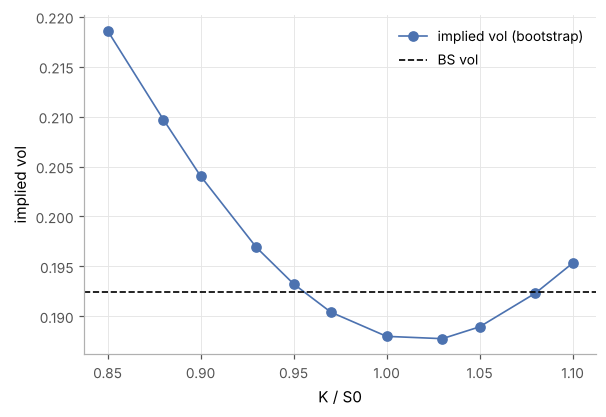

In [4]:
plt.figure(figsize=(6, 4))
plt.plot(strikes, ivs, "o-", label="implied vol (bootstrap)")
plt.axhline(sigma, color="k", ls="--", label="BS vol")
plt.xlabel("K / S0"); plt.ylabel("implied vol"); plt.legend()
plt.show()
# BS: same vol for every strike. real returns: implied vol goes up for low strikes = the skew of index options
# drawing days independently loses the vol clustering, so the tails get smoothed over a month
# -> the real market skew is steeper than this. next: GARCH for the vol, Heston or jumps for pricing